Forme : (5, 8)
Type  : uint8
[[0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0]]


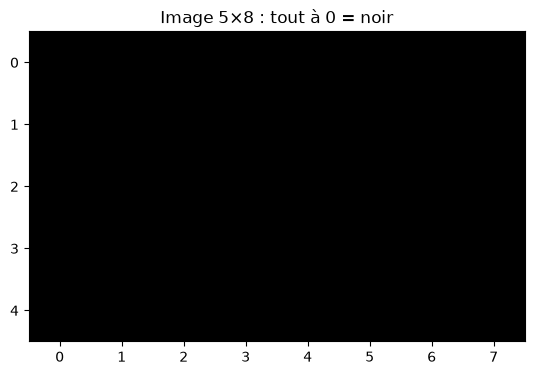

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Une image de 5 lignes × 8 colonnes, entièrement noire
img = np.zeros((5, 8), dtype=np.uint8)

print("Forme :", img.shape)   # (hauteur, largeur)
print("Type  :", img.dtype)
print(img)

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Image 5×8 : tout à 0 = noir")
plt.show()

[[255   0   0   0   0   0   0   0]
 [  0   0 200 200 200   0   0   0]
 [  0   0 200 200 200   0   0   0]
 [  0   0 200 200 200   0   0   0]
 [  0   0   0   0   0   0   0 128]]


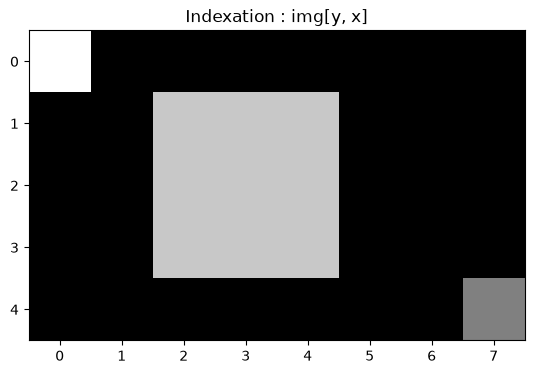

In [2]:
img = np.zeros((5, 8), dtype=np.uint8)

img[0, 0] = 255        # pixel en haut à gauche → blanc
img[4, 7] = 128        # pixel en bas à droite → gris moyen
img[1:4, 2:5] = 200    # rectangle : lignes 1 à 3, colonnes 2 à 4 → gris clair

print(img)

plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Indexation : img[y, x]")
plt.show()

Forme : (50, 256)
Pixel 200 + 100 →  naïf : 44 | clip : 255 | cv2.add : 255


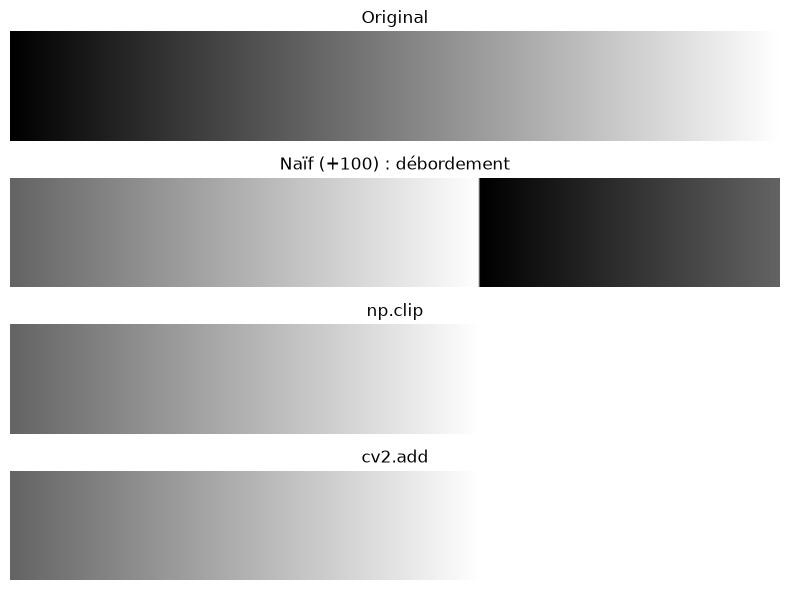

In [3]:
import cv2

# 1. Dégradé horizontal : 256 colonnes, de 0 (noir) à 255 (blanc)
degrade = np.tile(np.arange(256, dtype=np.uint8), (50, 1))   # 50 lignes identiques
print("Forme :", degrade.shape)

# 2. On éclaircit de +100… de trois façons
naif   = degrade + 100                                                   # ⚠️ débordement
clippe = np.clip(degrade.astype(np.int16) + 100, 0, 255).astype(np.uint8)
opencv = cv2.add(degrade, 100)                                           # saturation

print("Pixel 200 + 100 →  naïf :", naif[0, 200], "| clip :", clippe[0, 200], "| cv2.add :", opencv[0, 200, 0] if opencv.ndim == 3 else opencv[0, 200])

fig, axes = plt.subplots(4, 1, figsize=(8, 6))
for ax, im, titre in zip(axes, [degrade, naif, clippe, opencv],
                         ["Original", "Naïf (+100) : débordement", "np.clip", "cv2.add"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255, aspect="auto")
    ax.set_title(titre); ax.axis("off")
plt.tight_layout(); plt.show()

Forme : (100, 300, 3)
Pixel (50, 50) : [255   0   0]


/tmp/ipykernel_204508/3943282092.py:16: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_204508/3943282092.py:16: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/home/othmane/projets/imagerie-medicale-portfolio/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/othmane/projets/imagerie-medicale-portfolio/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


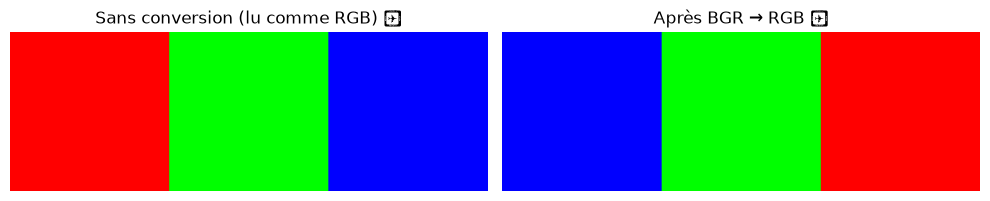

Forme d'un canal : (100, 300)


In [4]:
# Image couleur 100 × 300, au format OpenCV (BGR)
couleur = np.zeros((100, 300, 3), dtype=np.uint8)
couleur[:, 0:100]   = (255, 0, 0)   # canal 0 à 255 → pour OpenCV : BLEU
couleur[:, 100:200] = (0, 255, 0)   # canal 1 à 255 → VERT
couleur[:, 200:300] = (0, 0, 255)   # canal 2 à 255 → pour OpenCV : ROUGE

print("Forme :", couleur.shape)          # (hauteur, largeur, canaux)
print("Pixel (50, 50) :", couleur[50, 50])

rgb = cv2.cvtColor(couleur, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].imshow(couleur); axes[0].set_title("Sans conversion (lu comme RGB) ❌")
axes[1].imshow(rgb);     axes[1].set_title("Après BGR → RGB ✅")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

# Séparer les 3 canaux : chacun est une image en niveaux de gris
b, g, r = cv2.split(couleur)
print("Forme d'un canal :", b.shape)

Type : int16 | min : -1000 | max : 700


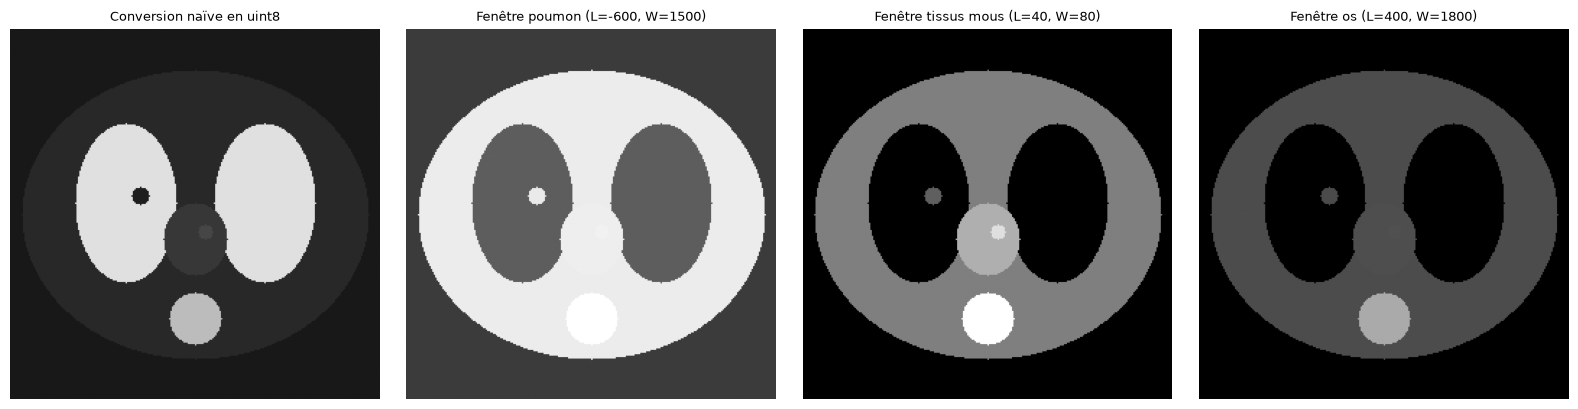

In [5]:
# 1. Coupe de thorax synthétique (256 x 256), en unités Hounsfield
H, W = 256, 256
yy, xx = np.mgrid[0:H, 0:W]

def ellipse(cy, cx, ry, rx):
    return ((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2 <= 1

ct = np.full((H, W), -1000, dtype=np.int16)        # air
ct[ellipse(128, 128, 100, 120)] = 40                # corps (tissus mous)
ct[ellipse(120, 80, 55, 35)]    = -800              # poumon gauche
ct[ellipse(120, 176, 55, 35)]   = -800              # poumon droit
ct[ellipse(115, 90, 6, 6)]      = 30                # petit nodule dans le poumon
ct[ellipse(200, 128, 18, 18)]   = 700               # vertèbre (os)
ct[ellipse(145, 128, 25, 22)]   = 55                # cœur
ct[ellipse(140, 135, 5, 5)]     = 70                # lésion à peine visible dans le cœur

print("Type :", ct.dtype, "| min :", ct.min(), "| max :", ct.max())

# 2. Fonction de fenêtrage
def fenetrage(img, centre, largeur):
    bas, haut = centre - largeur / 2, centre + largeur / 2
    img = np.clip(img.astype(np.float32), bas, haut)     # on coupe hors de la fenêtre
    return ((img - bas) / (haut - bas) * 255).astype(np.uint8)

# 3. Quatre affichages de la MÊME image
vues = {
    "Conversion naïve en uint8": ct.astype(np.uint8),
    "Fenêtre poumon (L=-600, W=1500)": fenetrage(ct, -600, 1500),
    "Fenêtre tissus mous (L=40, W=80)": fenetrage(ct, 40, 80),
    "Fenêtre os (L=400, W=1800)": fenetrage(ct, 400, 1800),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (titre, im) in zip(axes, vues.items()):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(titre, fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()